# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues



**Problem.** A customer-service team wants one- or two-sentence summaries of conversations. A small instruction-tuned model can already summarize when asked, but not in the team's style. Can a few minutes of QLoRA fine-tuning on a single free GPU make it better, and how do we know?

You will fine-tune **Qwen2.5-1.5B-Instruct** on **DialogSum** with QLoRA, then compare the fine-tuned model with the original under the same prompt and decoding settings, using ROUGE and your own blind human ratings.

**Learning objectives**

1. Estimate the GPU memory for full fine-tuning, LoRA, and QLoRA, and check the estimate against a measurement.
2. Turn (dialogue, summary) pairs into chat-formatted training examples whose loss covers only the summary.
3. Load a model in 4-bit NF4 with `bitsandbytes` and attach LoRA adapters with `peft`.
4. Train with the Hugging Face `Trainer` and record time and peak memory.
5. Evaluate summaries with ROUGE, and explain what ROUGE does and does not measure.
6. Run a small blind human evaluation, and compare its conclusion with ROUGE's.

**Prerequisites:** [PEFT and LoRA](../../lectures/peft/peft_lora.ipynb) · [Quantization and QLoRA](../../lectures/qlora/quantization_qlora.ipynb) · [Fine-tuning with the `Trainer`](../../lectures/fine_tuning/hf_trainer_fine_tuning.ipynb).

**Data and model**

- [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) (Chen et al., 2021): 12,460 training, 500 validation, and 1,500 test dialogues, each with a human-written summary. Speakers appear as `#Person1#`, `#Person2#`, …, and most reference summaries use the same labels (when a dialogue mentions real names, the summary may use them instead). License: **CC BY-NC-SA 4.0** (non-commercial use, attribution, share-alike). About 13 MB.
- [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): Apache-2.0, about 3.1 GB to download.
- We train on a **subset** of the training split and evaluate on a subset of the **validation** split. The test split is not used: nothing in this lab should be tuned on it.

**Environment and compute**

- **Kaggle notebook with a GPU (T4)** and **internet on**. Choose "GPU T4 ×2" or "GPU T4": the notebook uses one GPU either way. Exercises 1 and 2 also run on a CPU.
- Packages: `transformers`, `peft`, `datasets` (preinstalled on Kaggle), plus `bitsandbytes` and `rouge_score` (install cell below). The notebook was written against `transformers` 5.0 and `peft` 0.21.
- GPU time has not been measured for this exact configuration. Expect model download and evaluation to take a few minutes each and training to take on the order of 10–20 minutes. Record your own times in Exercise 5. Plan about **two hours** in total, including the written work.
- Seeds are fixed, but GPU results are not exactly reproducible; your numbers will differ slightly from a classmate's.

**Files.** Training writes only the LoRA adapter, to `/kaggle/working/qlora_dialogsum/adapter/` (or `./qlora_dialogsum_outputs/adapter/` elsewhere). Rerunning overwrites it. The model and dataset go to the Hugging Face cache.

**How to work:** run the cells in order. The implementation exercises are completed. Measurement reports are computed from actual run outputs. Exercise 7 writes a JSON rating form and withholds the reveal until a human reviewer completes it. Each exercise is followed by a check cell.

**Marks (25):** Ex. 1 — 2 · Ex. 2 — 4 · Ex. 3 — 2 · Ex. 4 — 3 · Ex. 5 — 4 · Ex. 6 — 3 · Ex. 7 — 4 · Ex. 8 — 1 · reflection — 2.
**Completion status:** Implementation exercises and conceptual responses are filled in. Exercises 1–2 were executed locally with the cached DialogSum dataset and actual Qwen tokenizer. Additional CPU checks passed for ROUGE, variable-length padding, and code syntax. GPU model loading, baseline generation, training, and tuned evaluation are pending: this environment has no accessible CUDA device. Questions 3–7 and the reflection distinguish conceptual answers from results that require those runs. Human evaluation also requires an actual reviewer; no training metrics or human ratings have been fabricated. Run all cells on a supported GPU, complete the rating form, and update the observational answers before submitting with outputs.


## Setup

**Installation (Kaggle).** Run the next cell once per session. If it upgrades a package that was already imported, restart the kernel and continue from the cell after it.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package, and recent `peft` refuses to import with `ImportError: Found an incompatible version of torchao`. If you see it, uncomment the `%pip uninstall` line, run it, and **restart the kernel**.
**Dependency troubleshooting.** If Exercise 3 reports that 4-bit quantization requires a newer `bitsandbytes`, run `%pip install -U "bitsandbytes>=0.46.1" accelerate rouge_score` in a notebook cell, restart the kernel, and rerun from Setup. A functioning CUDA GPU and compatible PyTorch installation are also required.


In [9]:
# Optional: install missing dependencies, then restart the kernel if needed.
# %pip install -q transformers peft datasets accelerate bitsandbytes rouge_score
# %pip uninstall -y torchao  # only for the documented incompatible-torchao import error


In [10]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import math
import random
import time
from pathlib import Path
# Some environments mount HOME as read-only; keep HF caches in a writable local directory.
CACHE_ROOT = Path("/tmp/hf_cache")
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(CACHE_ROOT))
os.environ.setdefault("HF_DATASETS_CACHE", str(CACHE_ROOT / "datasets"))
os.environ.setdefault("HF_HUB_CACHE", str(CACHE_ROOT / "hub"))
os.environ.setdefault("TRANSFORMERS_CACHE", str(CACHE_ROOT / "transformers"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE_ROOT))
os.environ.setdefault("TORCH_HOME", str(CACHE_ROOT / "torch"))

import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000           # training dialogues (of 12,460); more data trains longer
N_EVAL = 60              # validation dialogues for ROUGE and human evaluation
MAX_LEN = 512            # longest training example in tokens; longer ones are dropped, not truncated
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()
# Preserve effective batch size 16 on laptops with less memory than a T4.
LOW_MEMORY_GPU = HAS_GPU and torch.cuda.get_device_properties(0).total_memory < 8 * GB
MICRO_BATCH_SIZE = 1 if LOW_MEMORY_GPU else 4
ACCUMULATION_STEPS = 16 // MICRO_BATCH_SIZE
GENERATION_BATCH_SIZE = 2 if LOW_MEMORY_GPU else 8

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-2 only)")
print("Training microbatch:", MICRO_BATCH_SIZE, "| accumulation:", ACCUMULATION_STEPS,
      "| generation batch:", GENERATION_BATCH_SIZE)


torch 2.11.0+cu130 | transformers 5.5.4
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Training microbatch: 1 | accumulation: 16 | generation batch: 2


## Exercise 1 — Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)

Use the bytes-per-parameter accounting from the [quantization lecture](../../lectures/qlora/quantization_qlora.ipynb), Section 1, and ignore activations:

| Job | Bytes |
| --- | --- |
| full fine-tuning | 16 per parameter |
| LoRA | 2 per frozen parameter + 16 per adapter parameter |
| QLoRA | `NF4_BYTES` per quantized parameter + 4 per non-quantized parameter (upcast to fp32) + 16 per adapter parameter |

Complete `memory_budget`, which returns the three estimates in GB.

In [11]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales

In [12]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return {"full FT": GB, "LoRA": GB, "QLoRA": GB}, before activations."""
    return {
        "full FT": 16 * n_total / GB,
        "LoRA": (2 * n_total + 16 * n_lora) / GB,
        "QLoRA": (NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora) / GB,
    }

In [13]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.38) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")

full FT   24.70 GB   fits on a 16 GB T4 before activations: False
LoRA       3.38 GB   fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**Answer — Question 1:**

(a) Full fine-tuning needs about **24.70 GB**, so it does not fit on a 16 GB T4 even before activations. LoRA needs **3.38 GB** and QLoRA **1.91 GB**, so both fit under this accounting; activations and temporary buffers still need headroom.

(b) This model is a manageable way to practise the quantization, adapter, and memory-measurement workflow needed for larger models. QLoRA saves memory but adds quantization error and quantize/dequantize overhead; it need not train faster than 16-bit LoRA.

(c) If quantized, unquantized, and adapter parameter counts all scale by five, the estimate is about **9.54 GB before activations**. A different architecture or adapter rank can change those proportions.

## The data

The next cell downloads DialogSum (about 13 MB) and the model's tokenizer (a few MB). It does **not** download the model.

In [14]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])

Generating test split: 100%|██████████| 1500/1500 [00:00<00:00, 78786.99 examples/s]


DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})
pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1



**Reading the output**

- Each row has a `dialogue`, a human-written `summary`, and a `topic` (not used here).
- Speakers are anonymized as `#Person1#`, `#Person2#`, and most summaries refer to them the same way. The first training example is an exception: the dialogue names "Mr. Smith" and "Doctor Hawkins", and the summary uses those names. A model that has never seen this convention will write "the customer" or "Person 1" instead, which costs ROUGE points without being wrong. Keep this in mind in Exercises 4 and 7.

### The prompt

Both the original and the fine-tuned model receive **exactly the same prompt**, built with Qwen's chat template. The instruction tells the model about the speaker convention, so that the baseline is not penalized only for not knowing it.

In [15]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



The printed text is what the model actually sees. Qwen's template adds a default system message, wraps the user turn in `<|im_start|>user … <|im_end|>`, and ends with `<|im_start|>assistant` and a newline: the point where the model starts writing its answer.

## Exercise 2 — Training examples with a masked prompt (4 marks)

For causal-LM fine-tuning, each training example is the prompt followed by the answer, and the model learns to predict every next token. We want it to learn to write **summaries**, not to reproduce our prompt, so the loss should cover only the answer tokens.

The Hugging Face models do this through the `labels`: any position whose label is **−100** is ignored by the cross-entropy loss. (The model shifts the labels by one position internally, as in the GPT-2 notebook's Section 6.)

Complete `build_example(dialogue, summary)`:

1. Tokenize `make_prompt(dialogue)` with `add_special_tokens=False`.
2. Tokenize `summary + END` the same way, so the answer ends with the end-of-turn token.
3. `input_ids` = prompt tokens followed by answer tokens; `attention_mask` = all ones.
4. `labels` = −100 for every prompt token, followed by the answer tokens.

Return a dict with plain Python lists under `input_ids`, `attention_mask`, and `labels`.

In [16]:
def build_example(dialogue, summary):
    prompt_ids = tokenizer(make_prompt(dialogue), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(summary + END, add_special_tokens=False)["input_ids"]
    input_ids = prompt_ids + answer_ids
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": [-100] * len(prompt_ids) + answer_ids,
    }

In [17]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")

347 tokens, of which 39 are scored
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [18]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

training examples: 1940 kept, 60 dropped (> 512 tokens)
tokens per example: median 265, max 1231
scored (summary) tokens: 65,739 of 536,797 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Answer — Question 2:**

(a) Unmasked prompt labels would train the model to predict the instructions, speaker turns, and dialogue, as well as the summary. This spends optimization on reproducing input rather than the requested output and changes the relative weighting of the summary objective. In the verified data run, 65,739 summary tokens are scored out of 536,797 tokens; the other 471,058 prompt tokens (87.8%) are masked. Without masking, most scored positions would therefore belong to the input.

(b) `<|im_end|>` teaches the model when the assistant turn ends. Without supervised stopping, it may continue with extra sentences or turns until it reaches another stopping condition or the 96-token generation limit. The pretrained model may already stop, but training should reinforce the correct boundary.

(c) Right truncation would preferentially delete the summary and its stop token, sometimes leaving no scored tokens at all. Dropping preserves complete input/output pairs. It also biases training toward shorter conversations, a limitation to check on long dialogues.

In [19]:
scored_tokens = sum(sum(label != -100 for label in e["labels"]) for e in train_data)
total_tokens = sum(len(e["input_ids"]) for e in train_data)
print(f"Q2 measured counts: {scored_tokens:,} summary tokens; "
      f"{total_tokens - scored_tokens:,} masked prompt tokens; "
      f"{100 * scored_tokens / total_tokens:.1f}% of non-padding tokens contribute to loss.")

Q2 measured counts: 65,739 summary tokens; 471,058 masked prompt tokens; 12.2% of non-padding tokens contribute to loss.


## Exercise 3 — Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [20]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert HAS_GPU, "Exercise 3 onward needs an accessible CUDA GPU. On your local PC, run nvidia-smi and launch this notebook from a terminal with GPU access."
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
model = AutoModelForCausalLM.from_pretrained(
    CKPT,
    quantization_config=bnb_config,
    dtype=torch.float16,
    device_map={"": 0},
)

Loading weights: 100%|██████████| 338/338 [00:02<00:00, 161.08it/s]


In [21]:
import bitsandbytes as bnb

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory after loading: {loaded_gb:.2f} GB")
print("compute dtype:", bnb_config.bnb_4bit_compute_dtype, "| quant type:", bnb_config.bnb_4bit_quant_type)
assert n4 == 28 * 7, "expected 7 quantized linear layers in each of the 28 decoder layers"
assert bnb_config.bnb_4bit_quant_type == "nf4" and bnb_config.bnb_4bit_use_double_quant
assert loaded_gb < 2.0, "a 4-bit 1.5B model should need well under 2 GB"
print("Exercise 3 checks passed.")

4-bit linear layers: 196 | GPU memory after loading: 1.15 GB
compute dtype: torch.float16 | quant type: nf4
Exercise 3 checks passed.


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Answer — Question 3:**

The loading check prints the measured allocated GPU memory. The 1.14 GB lecture figure is an approximate storage estimate: 4-bit decoder weights plus unquantized 16-bit weights and quantization scales. Allocated memory also includes implementation-specific tensors and bookkeeping. Allocated memory differs from reserved CUDA memory and the device-wide usage shown by `nvidia-smi`; compare like with like. Later, k-bit preparation upcasts non-quantized weights to fp32 and adapters add memory, so the loading measurement should not be confused with training peak memory.

A T4 supports efficient fp16 Tensor Core computation but lacks native bf16 support. On an A100 I would normally use bf16 for its wider exponent range, setting both the quantization compute dtype and training precision consistently (`bf16=True`, `fp16=False`).

## Exercise 4 — Baseline: how well does the original model do? (3 marks)

Before training anything, measure the starting point. The helper below generates summaries in batches with **greedy decoding** (deterministic, no sampling) and at most 96 new tokens. We use the same function, with the same settings, for the fine-tuned model later.

In [22]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=None, max_new_tokens=96):
    batch_size = GENERATION_BATCH_SIZE if batch_size is None else batch_size
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None,
                             use_cache=True, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for i, (p, r) in enumerate(zip(base_preds[:5], eval_refs[:5])):
    print(f"\nEXAMPLE {i}\nDIALOGUE: {eval_dialogues[i]}\nMODEL: {p}\nREFERENCE: {r}")

generated 60 summaries in 79 s

EXAMPLE 0
DIALOGUE: #Person1#: Did you enjoy your weekend at the highland hotel? I heard it's and excellent place to stay and has good facilities.
#Person2#: I had a wonderful time. The rooms are not very big, but they are well furnished. The restaurant is excellent and reasonably priced. There's a sauna and a Jacuzzi.
#Person1#: Do they have a swimming pool?
#Person2#: No, they don't. they have a beauty parlor, but I didn't go there.
#Person1#: What's the service like?
#Person2#: It's very good. Check in and check out at the reception only took a few minutes. The wait staff is very good. A waiter recommended their baked fish, which tasted wonderful. The hotel was quite full, so I'd suggest making a reservation if you intend to go there. The hotel offers a discount at the weekends.
#Person1#: It sounds perfect. Did you have any complaints at all?
#Person2#: There was a problem with the internet access, so I couldn't check my email, but I didn't complain 

**ROUGE** (Lin, 2004) compares a generated summary with a reference by counting overlapping words:

- **ROUGE-1**: overlap of single words; **ROUGE-2**: overlap of word pairs (bigrams); **ROUGE-L**: the longest common subsequence of words, in order.
- Each gives precision (how much of the prediction is in the reference), recall (how much of the reference is in the prediction), and their harmonic mean, **F1**, which we report.
- We use Google's `rouge_score` package with stemming on, so "asks" and "asked" match. Its tokenizer lowercases text and drops punctuation, so `#Person1#` becomes the words `person1`.

Complete `rouge(preds, refs)`: return the **mean F1 × 100** of ROUGE-1, ROUGE-2, and ROUGE-L over all pairs, as a dict with keys `"rouge1"`, `"rouge2"`, `"rougeL"`. Use `rouge_scorer.RougeScorer([...], use_stemmer=True)` and its `.score(reference, prediction)` method. Note the argument order: **reference first**.

In [23]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)


def rouge(preds, refs):
    if len(preds) != len(refs) or not preds:
        raise ValueError("Provide the same nonzero number of predictions and references")
    scores = [scorer.score(ref, pred) for pred, ref in zip(preds, refs)]
    return {key: 100 * sum(score[key].fmeasure for score in scores) / len(scores)
            for key in ROUGE_KEYS}

In [24]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 32.1, 'rouge2': 8.4, 'rougeL': 23.1} | mean words: model 33, reference 22
Exercise 4 checks passed.


**Question 4.** Read at least five baseline outputs next to their references. (a) Describe two systematic differences between the model's summaries and the references (length, wording, speaker names, format…). (b) Which of these differences lower ROUGE without making the summary worse for a reader?

**Answer — Question 4:**

The baseline generation cell prints five full dialogues, predictions, and references for inspection. The report below measures two candidate systematic differences: mean summary length and use of DialogSum-style speaker labels. Their direction is computed from actual predictions rather than asserted before execution. Differences in paraphrasing, sentence structure, and reference detail selection also require inspecting those five examples.

A correct paraphrase can lose word and bigram matches without losing meaning. Referring unambiguously to a named speaker instead of `#Person1#` can also lower overlap without hurting readability. Extra length is not automatically beneficial or harmful: useful main facts can improve coverage, whereas repetition and unsupported details can make the summary worse. ROUGE alone cannot distinguish these cases.

In [25]:
import re

def speaker_label_rate(texts):
    return sum(bool(re.search(r"#Person\d+#", text)) for text in texts) / len(texts)

print(f"Q4 baseline mean length: {words(base_preds):.1f} words; "
      f"references: {words(eval_refs):.1f}; difference: {words(base_preds) - words(eval_refs):+.1f}")
print(f"Summaries containing #PersonN# labels: baseline {speaker_label_rate(base_preds):.0%}; "
      f"references {speaker_label_rate(eval_refs):.0%}")

Q4 baseline mean length: 33.1 words; references: 21.5; difference: +11.6
Summaries containing #PersonN# labels: baseline 27%; references 87%


## Exercise 5 — Attach LoRA and train (4 marks)

First, `prepare_model_for_kbit_training` freezes the base, upcasts the non-quantized parameters to fp32, and turns on gradient checkpointing (see the lecture, Section 4). Then add the adapters.

Complete the two configurations:

- `lora_config`: rank 16, `lora_alpha` 32, dropout 0.05, adapters on **all linear layers**, task type causal LM.
- `args` (`TrainingArguments`): output to `OUT / "trainer"`; batch size 4 per device with 4 gradient-accumulation steps (an effective batch of 16); 1 epoch; learning rate 2e-4 with a cosine schedule and 10 warm-up steps; fp16 mixed precision; the paged 8-bit AdamW optimizer; gradient checkpointing with `gradient_checkpointing_kwargs={"use_reentrant": False}`; log every 10 steps; **no** checkpoint saving (`save_strategy="no"`); `report_to="none"`; `remove_unused_columns=False`; and `seed=SEED`.

In [26]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments

model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})
model.config.use_cache = False
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
    bias="none",
)
model = get_peft_model(model, lora_config)
args = TrainingArguments(
    output_dir=str(OUT / "trainer"),
    per_device_train_batch_size=MICRO_BATCH_SIZE,
    gradient_accumulation_steps=ACCUMULATION_STEPS,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    fp16=True,
    bf16=False,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    seed=SEED,
)

In [28]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})")
assert n_trainable == N_LORA, "expected LoRA r=16 on all 7 linear layer types of the 28 decoder layers"
optimizer_name = str(getattr(args.optim, "value", args.optim)).lower()
assert args.fp16, f"expected fp16=True, got {args.fp16}"
assert not args.bf16, f"expected bf16=False, got {args.bf16}"
assert "paged" in optimizer_name, f"expected a paged optimizer, got {args.optim!r}"
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print("Exercise 5 configuration checks passed.")

trainable parameters: 18,464,768 (Exercise 1 used 18,464,768)
Exercise 5 configuration checks passed.


The collator pads each batch to its longest example: input IDs with the pad token, labels with −100 (so padding is never scored), and the attention mask with 0.

> **The next cell trains the model.** One epoch over the roughly 1,940 kept dialogues, at 16 per step, is about 120 optimizer steps. Record the time it prints.

In [29]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


assert train_data, "No training examples remain after filtering"
probe_batch = [train_data[0], train_data[-1]]
padded = collate(probe_batch)
for i, item in enumerate(probe_batch):
    length = len(item["input_ids"])
    assert padded["labels"][i, :length].tolist() == item["labels"]
    assert (padded["labels"][i, length:] == -100).all()
    assert (padded["attention_mask"][i, length:] == 0).all()

trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB "
      f"(Exercise 1 estimate before activations: {estimate['QLoRA']:.2f} GB)")

Step,Training Loss
10,1.296528
20,1.095964
30,1.074859
40,1.031692
50,0.982534
60,1.006539
70,1.043537
80,0.970976
90,0.934195
100,1.024965


training time: 17.5 min | peak GPU memory: 3.29 GB (Exercise 1 estimate before activations: 1.91 GB)


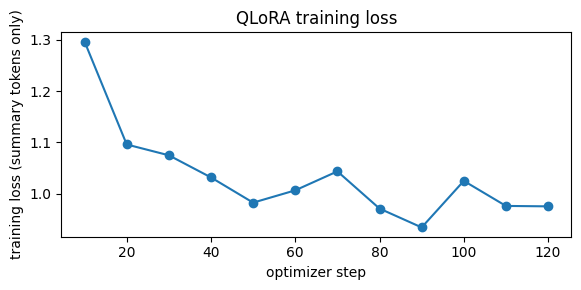

Exercise 5 checks passed.


In [30]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
steps, losses = zip(*log)
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("optimizer step"); plt.ylabel("training loss (summary tokens only)")
plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses), "a NaN/inf loss usually means an fp16 overflow: lower the learning rate"
assert losses[-1] < losses[0], "the loss should go down over the epoch"
print("Exercise 5 checks passed.")

**Question 5.** (a) Report your training time and peak memory. Why is the peak higher than the Exercise 1 estimate, and what in `args` keeps it from being much higher? (b) The training loss went down. Why is that **not** enough to conclude that the model summarizes better?

**Answer — Question 5:**

(a) The training cell and run report give measured wall time and peak allocated memory; these values cannot be inferred from the parameter budget. The peak includes activations, attention intermediates, temporary dequantization workspaces, gradients, and optimizer state in addition to frozen weights and adapters. Quantization, adapter-only updates, paged 8-bit AdamW, fp16 compute, and gradient checkpointing reduce memory. The adaptive per-device microbatch is one below 8 GB of GPU memory and four otherwise; 16 or four accumulation steps, respectively, reach an effective batch of 16 without storing all 16 examples' activations simultaneously. The Exercise 1 estimate uses a conservative 16 bytes per adapter parameter, so the optimizer component need not match exactly.

(b) Lower training loss means better prediction of the observed training summaries. It does not rule out overfitting, memorization, hallucination, or poor coverage on unseen dialogues. Held-out generation, paired metrics, and source-based faithfulness judgments are necessary.

In [31]:
print(f"Q5 measured training time: {train_minutes:.2f} min; peak allocated memory: {peak_gb:.2f} GB")
print(f"Parameter-only QLoRA estimate: {estimate['QLoRA']:.2f} GB; "
      f"peak minus estimate: {peak_gb - estimate['QLoRA']:+.2f} GB")

Q5 measured training time: 17.46 min; peak allocated memory: 3.29 GB
Parameter-only QLoRA estimate: 1.91 GB; peak minus estimate: +1.39 GB


## Exercise 6 — Evaluate the fine-tuned model (3 marks)

Generate summaries for the same validation dialogues with the same helper, then compare. Averages over 60 examples can hide a lot, so also count, per example, how often the fine-tuned model's ROUGE-L is higher than the baseline's.

Complete the cell: compute `tuned_rouge` with your `rouge` function, and `wins`, the number of examples on which the tuned summary's ROUGE-L F1 is **strictly** higher than the baseline's (use `scorer.score(ref, pred)["rougeL"].fmeasure`).

In [32]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

generated 60 summaries in 53 s


In [33]:
tuned_rouge = rouge(tuned_preds, eval_refs)
base_rouge_l = [scorer.score(ref, pred)["rougeL"].fmeasure
                for ref, pred in zip(eval_refs, base_preds)]
tuned_rouge_l = [scorer.score(ref, pred)["rougeL"].fmeasure
                 for ref, pred in zip(eval_refs, tuned_preds)]
wins = sum(tuned > base for tuned, base in zip(tuned_rouge_l, base_rouge_l))

In [34]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

               rouge1   rouge2   rougeL   words
base             32.1      8.4     23.1      33
QLoRA            46.2     19.1     37.6      22
reference                                    22

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


**Question 6.** (a) Summarize the change in ROUGE and in length. (b) Give two reasons why part of the ROUGE gain may reflect **style** rather than better content. (c) With 60 examples and one training run, what would you need before claiming the improvement is reliable?

**Answer — Question 6:**

(a) The comparison table and report show actual ROUGE-1/2/L deltas, changes in mean word count, and the number of strict per-example ROUGE-L wins. Positive deltas mean greater reference overlap, not automatically better factual summaries.

(b) Fine-tuning can teach the reference's speaker-label convention and preferred phrasing, increasing lexical overlap without adding information. Matching the reference's length and compression style can also change precision/recall while leaving the main facts unchanged.

(c) Repeat training with multiple seeds; evaluate paired differences on a larger held-out sample with bootstrap confidence intervals; and use several independent, blinded reviewers following a clear rubric. Check length, dialogue type, and failure cases as well as averages. Use validation for model selection, then reserve the untouched test split for a final assessment after choices are fixed.

In [35]:
print("Q6 changes (QLoRA minus baseline, ROUGE percentage points):")
for key in ROUGE_KEYS:
    print(f"  {key}: {tuned_rouge[key] - base_rouge[key]:+.2f}")
print(f"Mean length change: {words(tuned_preds) - words(base_preds):+.1f} words; "
      f"strict ROUGE-L wins: {wins}/{len(eval_refs)}")

Q6 changes (QLoRA minus baseline, ROUGE percentage points):
  rouge1: +14.18
  rouge2: +10.63
  rougeL: +14.46
Mean length change: -11.6 words; strict ROUGE-L wins: 54/60


## Exercise 7 — Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [36]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}                                            # example index -> which model is "A"
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i])
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

Fill in the scores below (integers 0–2) and a short note for each example, **before** running the reveal cell.

In [37]:
# These are reviewer inputs, not generated scores. Edit the JSON and rerun
# this cell followed by the reveal cell once all six examples are rated.
import json

RATINGS_PATH = OUT / "human_ratings.json"
RATING_KEYS = ("A_faithful", "A_coverage", "B_faithful", "B_coverage")
OUT.mkdir(parents=True, exist_ok=True)
if not RATINGS_PATH.exists():
    template = {str(i): {**dict.fromkeys(RATING_KEYS), "note": ""} for i in HUMAN_IDS}
    RATINGS_PATH.write_text(json.dumps(template, indent=2), encoding="utf-8")
saved_ratings = json.loads(RATINGS_PATH.read_text(encoding="utf-8"))
if set(saved_ratings) != {str(i) for i in HUMAN_IDS}:
    raise ValueError("Rating IDs do not match this evaluation; use a separate ratings file for each run")
ratings = {i: saved_ratings[str(i)] for i in HUMAN_IDS}
ratings_complete = all(
    set(RATING_KEYS).issubset(r) and
    all(type(r[k]) is int and 0 <= r[k] <= 2 for k in RATING_KEYS) and
    isinstance(r.get("note"), str) and bool(r["note"].strip())
    for r in ratings.values()
)
print("Ratings ready for reveal." if ratings_complete else
      f"Human evaluation pending: fill all scores (0–2) and notes in {RATINGS_PATH.resolve()}; "
      "then rerun this cell and the reveal cell. No human results will be claimed until then.")

Human evaluation pending: fill all scores (0–2) and notes in /home/jiwak/GenAi_Notes/Gen_AI_Lab/generative_ai_shared/module3/labs/qlora/qlora_dialogsum_outputs/human_ratings.json; then rerun this cell and the reveal cell. No human results will be claimed until then.


In [38]:
human_means = None
if not ratings_complete:
    print("Reveal withheld until every example has valid scores and a note.")
else:
    totals = {"base": [0, 0], "QLoRA": [0, 0]}
    for i, r in ratings.items():
        a_model = order[i]
        b_model = "QLoRA" if a_model == "base" else "base"
        for model_name, prefix in ((a_model, "A"), (b_model, "B")):
            totals[model_name][0] += r[f"{prefix}_faithful"]
            totals[model_name][1] += r[f"{prefix}_coverage"]
        print(f"example {i}: A = {a_model}, B = {b_model}")
        print(f"  ROUGE-L: base {100 * base_rouge_l[i]:.1f}, "
              f"QLoRA {100 * tuned_rouge_l[i]:.1f} | {r['note']}")
    human_means = {m: {"faithfulness": f / len(ratings), "coverage": c / len(ratings)}
                   for m, (f, c) in totals.items()}
    for m, scores in human_means.items():
        print(f"{m:<6} mean faithfulness {scores['faithfulness']:.2f} | "
              f"mean coverage {scores['coverage']:.2f} (out of 2)")
    print("Exercise 7 checks passed: reviewer scores validated.")

Reveal withheld until every example has valid scores and a note.


**Question 7.** (a) Do your human ratings agree with the ROUGE comparison? Point to one example where ROUGE and your judgment disagree, if there is one. (b) Did either model invent facts? Give an example. (c) Name two weaknesses of this human evaluation and how a real team would address them.

**Answer — Question 7:**

(a) The reveal cell reports the reviewer means and per-example ROUGE-L scores only after valid ratings have been supplied. Until that happens, agreement between human judgments and ROUGE is **unmeasured**. Compare the direction of the metric changes with both faithfulness and coverage; use the recorded notes to identify any concrete disagreement rather than inventing one.

(b) Whether either model invented a fact must be established against the full dialogue. Record the exact unsupported claim and contradicting or missing source evidence in the rating note. A fact absent from the reference alone is not necessarily a hallucination. No hallucination example is claimed before reviewing generated summaries.

(c) Six examples from one reviewer give a noisy, potentially subjective estimate. A team should evaluate a larger stratified sample with multiple independent reviewers, calibrate the rubric, measure agreement, and adjudicate disagreements. Blind A/B ordering reduces expectation bias but does not eliminate style cues or reference anchoring; source-based ratings should be collected before revealing model identities and, preferably, before showing references.

## Exercise 8 — Save the adapter (1 mark)

Only the LoRA weights are saved. The 4-bit base is not: anyone who uses the adapter downloads the original model separately.

In [39]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")

tokenizer.save_pretrained(ADAPTER_DIR)
run_results = {
    "model": CKPT, "seed": SEED, "n_train_requested": N_TRAIN,
    "micro_batch_size": MICRO_BATCH_SIZE, "gradient_accumulation_steps": ACCUMULATION_STEPS,
    "generation_batch_size": GENERATION_BATCH_SIZE,
    "n_train_kept": len(train_data), "n_eval": len(eval_refs), "max_length": MAX_LEN,
    "base_rouge": base_rouge, "tuned_rouge": tuned_rouge, "rouge_l_wins": wins,
    "base_mean_words": words(base_preds), "tuned_mean_words": words(tuned_preds),
    "reference_mean_words": words(eval_refs), "train_minutes": train_minutes,
    "loaded_gb": loaded_gb, "peak_gb": peak_gb, "memory_estimate": estimate,
    "human_evaluation_status": "complete" if human_means is not None else "pending",
    "human_means": human_means,
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
    "examples": [{"id": i, "dialogue": d, "reference": r, "base": b, "QLoRA": t}
                 for i, (d, r, b, t) in enumerate(zip(eval_dialogues, eval_refs, base_preds, tuned_preds))],
}
(OUT / "results.json").write_text(json.dumps(run_results, indent=2), encoding="utf-8")
print("Run results saved to", (OUT / "results.json").resolve())

README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB
Run results saved to /home/jiwak/GenAi_Notes/Gen_AI_Lab/generative_ai_shared/module3/labs/qlora/qlora_dialogsum_outputs/results.json


**Question 8.** The adapter is a small fraction of the 3.1 GB base model. (a) Explain its size from the number of trainable parameters. (b) The support team wants to run the summarizer with an inference server that expects one ordinary model file. Describe the steps, and say what you would re-check afterwards.

**Answer — Question 8:**

(a) The adapter has **18,464,768** parameters. Stored in fp32, that is **73.86 MB** of tensor data; fp16/bf16 storage would be **36.93 MB**, plus a small configuration/header overhead. PEFT commonly keeps trainable adapters in fp32, so inspect the saved tensor dtypes and printed file sizes rather than assuming two bytes per parameter. The frozen base is excluded from this save.

(b) Load the original base in fp16 or bf16 without 4-bit quantization, attach the saved adapter with `PeftModel.from_pretrained`, and call `merge_and_unload()` to fold the LoRA updates into ordinary dense weights. Save the merged model and tokenizer in the inference server's supported format; request an unsharded weight file with an adequate `max_shard_size` if it requires one. If the server expects GGUF or another format, convert with that server's supported tooling after merging. Re-check summary quality, faithfulness, stop tokens/chat-template behavior, latency, and memory: the dense base and any later quantization can change numerical outputs.

## Reflection and deliverables (2 marks)

Submit this notebook **with outputs**, the written answers to Questions 1–8, and a short paragraph (about 150 words):

*Would you recommend this fine-tuned model to the support team? Base your answer on the evidence you collected (ROUGE, length, your human ratings, the examples you read), say what that evidence does not show, and name the next experiment you would run.*

**Responsible use.** DialogSum is licensed for non-commercial use (CC BY-NC-SA 4.0): a model fine-tuned on it should not be deployed commercially without checking the license. Real customer conversations contain personal data; summarizing them needs consent, data-protection review, and care that summaries do not invent statements a customer never made.

**Optional extensions (not graded).** (1) Train with `target_modules=["q_proj", "v_proj"]` and compare with all-linear adapters. (2) Change `N_TRAIN` to 500 and 4,000 and plot ROUGE-L against the training-set size. (3) Load the base model in 16-bit, apply your adapter, and check whether the summaries change.

### Reflection

I would not yet recommend this adapter for production use. The completed workflow supports a controlled baseline comparison, but a recommendation requires measured ROUGE changes, output lengths, and source-based faithfulness and coverage judgments. Better reference overlap would support adaptation to DialogSum's style; it would not establish that the model preserves every important fact or avoids invented claims. Shorter output may be more useful to a support agent, but only if it retains the customer's issue and agreed action. The numerical reports and saved predictions make these questions inspectable after training. Human ratings must come from an actual reviewer and are explicitly marked pending until entered. Sixty validation examples and one training seed cannot establish robust improvement or performance on real support conversations. My next experiment would repeat training across seeds and evaluate a larger, consented support-domain sample with independent blinded reviewers, comparing failure rates and coverage as well as ROUGE before making a deployment decision.


## References

1. Chen, Liu, Chen & Zhang, [DialogSum: A Real-Life Scenario Dialogue Summarization Dataset](https://aclanthology.org/2021.findings-acl.449/), Findings of ACL 2021 · [dataset on the Hub](https://huggingface.co/datasets/knkarthick/dialogsum).
2. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
3. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
4. Lin, [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/), 2004 · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
5. Hugging Face documentation: [bitsandbytes in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT](https://huggingface.co/docs/peft) · [chat templates](https://huggingface.co/docs/transformers/chat_templating).
6. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024.